# Holdout method: five stratified 70/15/15 splits

Run the transformation notebook first. This notebook reads the saved transformed training/validation and development/test matrices for each seed and selector. It benchmarks logistic regression, random forest, XGBoost, LightGBM and stacking against a **training-prior dummy classifier**.

Base classifiers fit directly on the exported transformed matrices. Stacking additionally refits complete transformations inside its inner folds, using source rows from the same exported membership, to avoid leaking supervised selection into its meta-model.

Both selectors and all fixed candidates are evaluated for comparison. Choose the preferred configuration by validation only, not by test rankings. The positive class is **gallstones present**. Mean and sample variance describe the five overlapping splits, not independent confidence intervals.


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Locate the project when launched from its root or notebooks directory.
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "utils.py").is_file() and (p / "data/raw/dataset_gallstone").is_file())
sys.path.insert(0, str(ROOT))
from utils import (DEFAULT_SEEDS, DATASET_DIR, REPORT_METRICS, WORKFLOW_MODELS,
                   workflow_data, require_exports, prepare_holdout_exports,
                   load_pickle, continuous_columns, plot_evaluation)
sns.set_theme(style="whitegrid")
from utils import run_holdout_workflow
X, y, manifest = require_exports()
display(pd.DataFrame({"seed": manifest["seeds"]}))


,seed
0,42
1,7
2,21
3,84
4,123


## 1. Fit, benchmark and save pickle models

Every final model is refitted on the 85% development rows and saved to `models/holdout/seed_<seed>/<selector>_<model>.pkl`. Pickles include the fitted transformation pipeline and accept original predictor columns. Validation and test scores are kept separate.


In [2]:
metrics, summary = run_holdout_workflow()
display(metrics[["seed", "selection", "model", "evaluation", "accuracy", "roc_auc", "fnr", "FN", "TP"]])
display(summary.loc[summary.evaluation == "test"])


/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:356: RuntimeWarning: divide by zero encountered in matmul
  X_grad = X.T @ grad_pointwise
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:356: RuntimeWarning: overflow encountered in matmul
  X_grad = X.T @ grad_pointwise
/Users/quydu

/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2820: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2820: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2820: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights_xp + inter

/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:356: RuntimeWarning: divide by zero encountered in matmul
  X_grad = X.T @ grad_pointwise
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:356: RuntimeWarning: overflow encountered in matmul
  X_grad = X.T @ grad_pointwise
/Users/quydu

/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning

/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:356: RuntimeWarning: divide by zero encountered in matmul
  X_grad = X.T @ grad_pointwise
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:356: RuntimeWarning: overflow encountered in matmul
  X_grad = X.T @ grad_pointwise
/Users/quydu

...

/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:356: RuntimeWarning: divide by zero encountered in matmul
  X_grad = X.T @ grad_pointwise
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:356: RuntimeWarning: overflow encountered in matmul
  X_grad = X.T @ grad_pointwise
/Users/quydu

Holdout seed 123 complete


/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2820: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2820: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  w

,seed,selection,model,evaluation,accuracy,roc_auc,fnr,FN,TP
0,42,rfe,logistic,validation,0.708333,0.798611,0.208333,5,19
1,42,rfe,logistic,test,0.812500,0.888889,0.083333,2,22
2,42,rfe,random_forest,validation,0.687500,0.715278,0.333333,8,16
3,42,rfe,random_forest,test,0.791667,0.848958,0.083333,2,22
4,42,rfe,xgboost,validation,0.645833,0.727431,0.333333,8,16
...,...,...,...,...,...,...,...,...,...
115,123,cart,lightgbm,test,0.812500,0.899306,0.125000,3,21
116,123,cart,stacking,validation,0.750000,0.791667,0.125000,3,21
117,123,cart,stacking,test,0.833333,0.914931,0.083333,2,22
118,123,cart,dummy_prior,validation,0.500000,0.500000,0.000000,0,24


,model,selection,evaluation,metric,n_runs,mean,variance,std
0,dummy_prior,cart,test,accuracy,5,0.500000,0.000000,0.000000
1,dummy_prior,cart,test,f1,5,0.666667,0.000000,0.000000
2,dummy_prior,cart,test,fnr,5,0.000000,0.000000,0.000000
3,dummy_prior,cart,test,precision,5,0.500000,0.000000,0.000000
4,dummy_prior,cart,test,recall,5,1.000000,0.000000,0.000000
...,...,...,...,...,...,...,...,...
156,xgboost,rfe,test,fnr,5,0.141667,0.004861,0.069722
157,xgboost,rfe,test,precision,5,0.737853,0.001940,0.044047
158,xgboost,rfe,test,recall,5,0.858333,0.004861,0.069722
159,xgboost,rfe,test,roc_auc,5,0.844444,0.000913,0.030210


## 2. Validation-selected results and benchmark comparison

The dummy model predicts the training class prior, giving ROC-AUC 0.5. Its accuracy and FNR show how a feature-free classifier behaves at threshold 0.5. Logistic regression is also an interpretable model benchmark.


,seed,model,selection
0,42,logistic,cart
1,7,logistic,rfe
2,21,logistic,cart
3,84,logistic,rfe
4,123,logistic,cart


,mean,var,std
accuracy,0.800000,0.000998,0.031595
roc_auc,0.882986,0.001083,0.032908
fnr,0.108333,0.005729,0.075691
recall,0.891667,0.005729,0.075691
specificity,0.708333,0.003472,0.058926
precision,0.755108,0.001072,0.032737
f1,0.815956,0.001130,0.033608


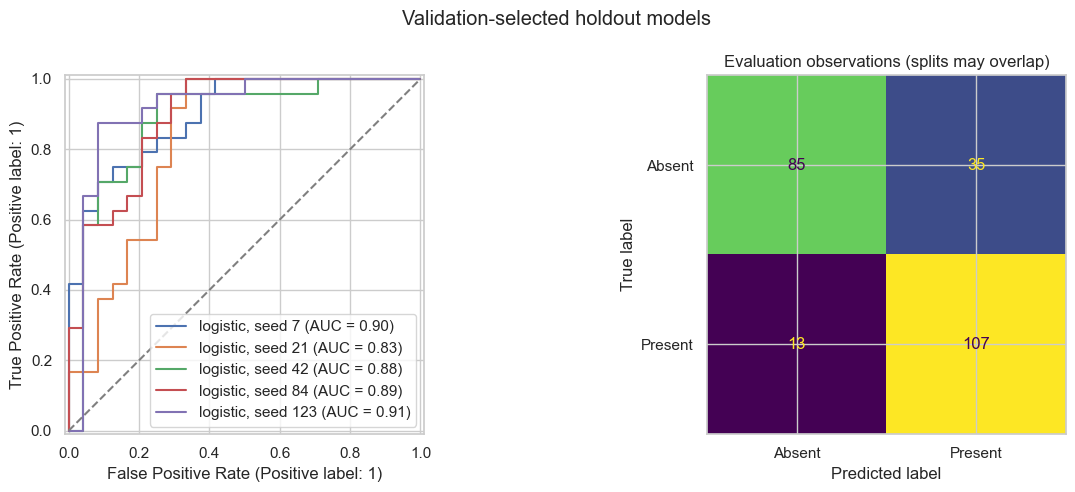

,model,selection,evaluation,metric,n_runs,mean,variance,std
0,dummy_prior,cart,test,accuracy,5,0.500000,0.000000,0.000000
2,dummy_prior,cart,test,fnr,5,0.000000,0.000000,0.000000
5,dummy_prior,cart,test,roc_auc,5,0.500000,0.000000,0.000000
14,dummy_prior,rfe,test,accuracy,5,0.500000,0.000000,0.000000
16,dummy_prior,rfe,test,fnr,5,0.000000,0.000000,0.000000
19,dummy_prior,rfe,test,roc_auc,5,0.500000,0.000000,0.000000
28,lightgbm,cart,test,accuracy,5,0.770833,0.000868,0.029463
30,lightgbm,cart,test,fnr,5,0.150000,0.003993,0.063191
33,lightgbm,cart,test,roc_auc,5,0.824479,0.001870,0.043239
42,lightgbm,rfe,test,accuracy,5,0.787500,0.001606,0.040074


In [3]:
RESULTS = ROOT / "results" / "holdout"
winners = pd.read_csv(RESULTS / "validation_winners.csv")
predictions = pd.read_csv(RESULTS / "predictions.csv")
selected_metrics = metrics.loc[metrics.evaluation == "test"].merge(winners, on=["seed", "model", "selection"])
display(winners)
display(selected_metrics[list(REPORT_METRICS)].agg(["mean", "var", "std"]).T)
selected_metrics.to_csv(RESULTS / "selected_test_metrics.csv", index=False)
selected_predictions = predictions.loc[predictions.evaluation == "test"].merge(winners, on=["seed", "model", "selection"])
plot_evaluation(selected_predictions, "Validation-selected holdout models", RESULTS / "selected_roc_confusion.png")
comparison = summary.loc[(summary.evaluation == "test") & summary.metric.isin(["accuracy", "roc_auc", "fnr"])]
display(comparison)
